# CS308 Лаборатори 10 — Transformers: монгол мэдээ ангилах

**Оюутан:** Б. Өсөхбаяр (B231910012)
**Датасет:** Eduge news corpus — 73,875 мэдээ, 9 ангилал
**Загвар:** `tugstugi/bert-base-mongolian-cased`

> ### ⚠️ Эхлэхээсээ өмнө
> `Runtime` → `Change runtime type` → **T4 GPU** сонгоно.
> GPU-гүйгээр бүх 6 даалгавар ~3 цаг болно; T4 дээр ~10-15 мин.
> Доорх эхний нүд сангуудыг автоматаар суулгана.

In [ ]:
# ═══ Colab: шаардлагатай сангуудыг суулгах (~1 мин) ═══
# protobuf-ийг ЗААВАЛ шинэчилнэ: хуучин хувилбар дээр монгол BERT-ийн
# SentencePiece tokenizer ачаалагдахгүй ("tiktoken is required" алдаа өгнө).
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers", "datasets", "sentencepiece", "accelerate",
                "-U", "protobuf"], check=True)
print("✓ суулгалт дууслаа")

import google.protobuf, transformers, torch
print("protobuf    :", google.protobuf.__version__)
print("transformers:", transformers.__version__)
print("CUDA        :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU алга")

# Лабораторийн ажил: Transformers ашиглан монгол хэлний мэдээг ангилах

**Датасет:** Eduge news corpus (`tugstugi/mongolian-nlp`) — монгол хэлний мэдээг 9 ангилалд хуваасан корпус
**Загвар:** `tugstugi/bert-base-mongolian-cased` (монгол хэл дээр урьдчилан сургасан BERT)
**Хугацаа:** ~2 цаг (сургалтын хэсэг GPU/MPS дээр 10-25 мин)

---

## Ажлын зорилго

Энэ лабораторийн ажлыг гүйцэтгэснээр оюутан дараах чадварыг эзэмшинэ:

1. Бодит, цэвэрлэгдээгүй текст корпусыг ачаалж, ангиллын тэнцвэржилтийг шинжлэх
2. Subword tokenizer монгол хэлний үг хэрхэн задалж байгааг ойлгох (fertility rate)
3. Урьдчилан сургасан encoder загварыг **sequence classification** бодлогод fine-tune хийх
4. `Trainer` API-г ашиглан сургалтын цикл, метрик тооцоолол, early stopping зохион байгуулах
5. Classical baseline (TF-IDF + Logistic Regression) ба transformer-ийн гүйцэтгэлийг харьцуулах
6. Confusion matrix, алдааны шинжилгээ хийж, загварын сул талыг тайлбарлах

## Урьдчилсан шаардлага

- Python 3.10-3.12 (доорх **Анхааруулга** хэсгийг уншина уу)
- PyTorch суусан орчин (CUDA, Apple MPS эсвэл CPU)
- Интернэт холболт (датасет болон загвар татах)

> ### ⚠️ Анхааруулга: Python хувилбар
>
> Та Python **3.14** дээр ажиллаж байна. PyTorch/transformers-ийн тогтвортой wheel энэ хувилбар дээр байхгүй байх магадлалтай.
> Хэрэв `import torch` алдаа өгвөл тусдаа орчин үүсгэнэ:
>
> ```bash
> uv venv --python 3.12 ~/Documents/ml_env/.venv312
> source ~/Documents/ml_env/.venv312/bin/activate
> uv pip install torch transformers datasets scikit-learn pandas matplotlib seaborn accelerate ipykernel
> python -m ipykernel install --user --name ml312 --display-name "Python 3.12 (ML)"
> ```
>
> Дараа нь Jupyter дотроос **Kernel → Change Kernel → Python 3.12 (ML)** сонгоно.

## 0. Орчин бэлтгэх

In [ ]:
# Шаардлагатай сангуудыг суулгах (нэг удаа)
# !pip install -q torch transformers datasets scikit-learn pandas matplotlib seaborn accelerate

In [21]:
import os, re, time, json, random, inspect
import numpy as np
import pandas as pd
import torch

import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Төхөөрөмж сонгох: CUDA > Apple MPS > CPU
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("torch:", torch.__version__)
print("device:", DEVICE)

import transformers
print("transformers:", transformers.__version__)

torch: 2.14.1
device: mps
transformers: 5.22.1


### Тохиргооны блок

Доорх утгуудыг өөрчилж туршилт хийнэ. `SAMPLE_PER_CLASS`-г багасгаснаар CPU дээр ч ажиллах боломжтой.

In [22]:
CONFIG = {
    "model_name": "tugstugi/bert-base-mongolian-cased",
    "max_length": 256,          # токены урт (мэдээний эхний 256 токен)
    "sample_per_class": 1500,   # ангилал тус бүрээс авах дээж (None = бүгд)
    "batch_size": 16,
    "eval_batch_size": 32,
    "epochs": 2,
    "lr": 2e-5,
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "output_dir": "./eduge_bert",
}

# Монгол хэлний бусад сонголтууд (Даалгавар 5-д ашиглана):
#   "tugstugi/bert-base-mongolian-uncased"
#   "tugstugi/bert-large-mongolian-cased"
#   "bayartsogt/mongolian-roberta-base"
#   "xlm-roberta-base"                  # multilingual baseline
#   "bert-base-multilingual-cased"      # multilingual baseline

CONFIG

{'model_name': 'tugstugi/bert-base-mongolian-cased',
 'max_length': 256,
 'sample_per_class': 1500,
 'batch_size': 16,
 'eval_batch_size': 32,
 'epochs': 2,
 'lr': 2e-05,
 'warmup_ratio': 0.1,
 'weight_decay': 0.01,
 'output_dir': './eduge_bert'}

## 1. Өгөгдөл ачаалах

Eduge корпус нь gzip хэлбэрээр GitHub дээр байрладаг. **Анхаарах зүйл:** баганын нэр `' label'`
гэж урдаа зайтай бичигдсэн байдаг — үүнийг цэвэрлэхгүй бол `df["label"]` алдаа өгнө.

In [ ]:
URL = ("https://raw.githubusercontent.com/tugstugi/mongolian-nlp/master/datasets/eduge.csv.gz")

df = pd.read_csv(URL, compression="gzip")
print("Эх баганууд:", list(df.columns))

# Баганын нэрийг цэвэрлэх
df.columns = [c.strip() for c in df.columns]
df["label"] = df["label"].astype(str).str.strip()
df["news"] = df["news"].astype(str).str.strip()

print("Цэвэрлэсний дараа:", list(df.columns))
print("Нийт мөр:", len(df))
df.head(3)

Эх баганууд: ['news', ' label']
Цэвэрлэсний дараа: ['news', 'label']
Нийт мөр: 75661


,news,label
0,Киноны кадраас «Юрийн галавын үе» кино проката...,урлаг соёл
1,“Universal” кино компани Жадд Апатоугийн найру...,урлаг соёл
2,Баз Лурманы бүтээж байгаа “The Get Down” хөгжм...,урлаг соёл


In [24]:
# Хоосон болон давхардсан мөрийг арилгах
before = len(df)
df = df[df["news"].str.len() > 20]
df = df.drop_duplicates(subset=["news"]).reset_index(drop=True)
print(f"{before} -> {len(df)} мөр ({before - len(df)} мөр хасагдлаа)")

75661 -> 73875 мөр (1786 мөр хасагдлаа)


## 2. Хайгуулын шинжилгээ (EDA)

Сургалт эхлэхээс өмнө **ангиллын тэнцвэржилт** болон **текстийн уртыг** заавал шалгана.
Эдгээр нь `max_length`, loss функцийн жин, метрик сонголтод шууд нөлөөлнө.

label
улс төр         13405
спорт           13401
эдийн засаг     12349
хууль            8164
урлаг соёл       6966
технологи        5431
байгал орчин     4937
эрүүл мэнд       4781
боловсрол        4441
Name: count, dtype: int64

Нийт ангилал: 9
Хамгийн их/бага харьцаа: 3.0x


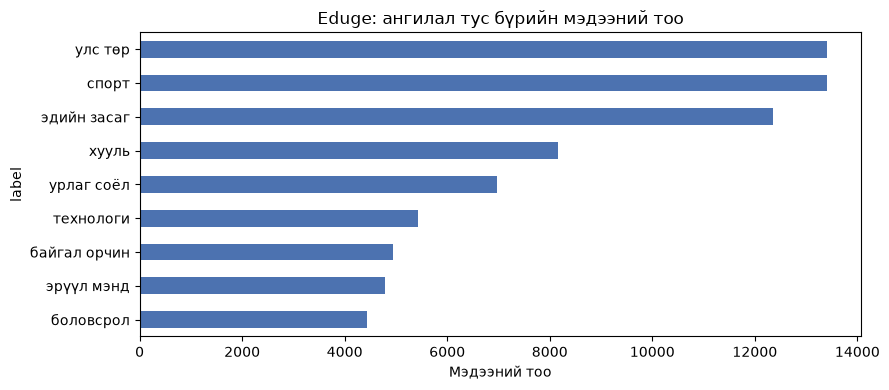

In [25]:
counts = df["label"].value_counts()
print(counts)
print("\nНийт ангилал:", df["label"].nunique())
print("Хамгийн их/бага харьцаа: %.1fx" % (counts.max() / counts.min()))

fig, ax = plt.subplots(figsize=(9, 4))
counts.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Eduge: ангилал тус бүрийн мэдээний тоо")
ax.set_xlabel("Мэдээний тоо")
plt.tight_layout()
plt.show()

count    73875.0
mean       320.2
std        424.4
min          1.0
25%         99.0
50%        167.0
75%        360.0
max       9679.0
Name: n_words, dtype: float64


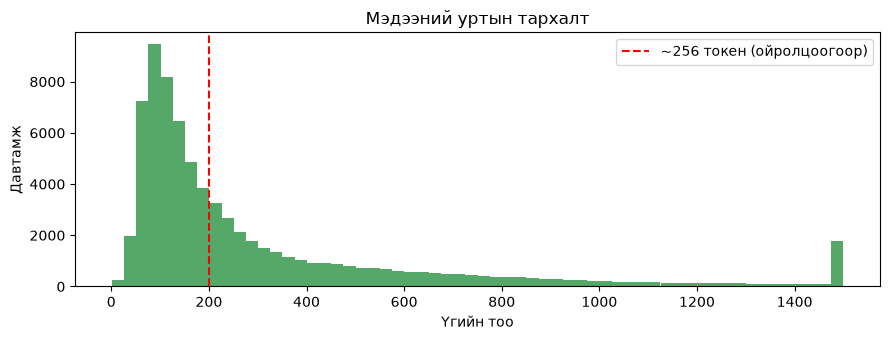

In [26]:
# Текстийн урт (үгээр)
df["n_words"] = df["news"].str.split().str.len()
print(df["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df["n_words"].clip(upper=1500), bins=60, color="#55A868")
ax.axvline(200, color="red", ls="--", label="~256 токен (ойролцоогоор)")
ax.set_xlabel("Үгийн тоо"); ax.set_ylabel("Давтамж")
ax.set_title("Мэдээний уртын тархалт")
ax.legend(); plt.tight_layout(); plt.show()

> **Асуулт 1.** Мэдээний хэдэн хувь нь 256 токеноос урт вэ? `max_length=256` гэж тасалснаар
> ямар мэдээлэл алдагдах вэ? Ангиллын хувьд энэ хэр чухал вэ? (Хариултаа доорх markdown нүдэнд бичнэ.)

**Хариулт 1:**

_(энд бичнэ)_

## 3. Шошго кодлох ба өгөгдлийг хуваах

Ангиллын тэнцвэргүй байдлыг хадгалахын тулд **stratified split** ашиглана (70/15/15).

In [27]:
from sklearn.model_selection import train_test_split

# Дээж авах (лабораторийн хугацааг багасгах зорилгоор).
# ЗАСВАР: эх notebook дээр энэ блок ХОЁР УДАА давтагдсан байсан — нэгийг нь үлдээв.
if CONFIG["sample_per_class"]:
    df_s = pd.concat(
        [g.sample(n=min(len(g), CONFIG["sample_per_class"]), random_state=SEED)
         for _, g in df.groupby("label")],
        ignore_index=True,
    )
else:
    df_s = df.copy()

labels   = sorted(df_s["label"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
df_s["y"] = df_s["label"].map(label2id)

print("Ангилал:", label2id)
print("Дээжийн хэмжээ:", len(df_s))

Ангилал: {'байгал орчин': 0, 'боловсрол': 1, 'спорт': 2, 'технологи': 3, 'улс төр': 4, 'урлаг соёл': 5, 'хууль': 6, 'эдийн засаг': 7, 'эрүүл мэнд': 8}
Дээжийн хэмжээ: 13500
Ангилал: {'байгал орчин': 0, 'боловсрол': 1, 'спорт': 2, 'технологи': 3, 'улс төр': 4, 'урлаг соёл': 5, 'хууль': 6, 'эдийн засаг': 7, 'эрүүл мэнд': 8}
Дээжийн хэмжээ: 13500


In [28]:
train_df, tmp_df = train_test_split(
    df_s, test_size=0.30, stratify=df_s["y"], random_state=SEED)
val_df, test_df = train_test_split(
    tmp_df, test_size=0.50, stratify=tmp_df["y"], random_state=SEED)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):6d}")

train:   9450
val  :   2025
test :   2025


## 4. Baseline: TF-IDF + Logistic Regression

Transformer хэрэглэхээс өмнө **энгийн baseline** тавих нь зайлшгүй. Хэрэв BERT энэ baseline-г
мэдэгдэхүйц давахгүй бол fine-tuning-ийн тохиргоонд алдаа байна гэсэн үг.

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

t0 = time.time()
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(train_df["news"])
Xte = vec.transform(test_df["news"])

clf = LogisticRegression(max_iter=1000, C=5.0, n_jobs=-1)
clf.fit(Xtr, train_df["y"])
pred_base = clf.predict(Xte)

BASELINE = {
    "accuracy": accuracy_score(test_df["y"], pred_base),
    "macro_f1": f1_score(test_df["y"], pred_base, average="macro"),
}
print("Baseline:", {k: round(v, 4) for k, v in BASELINE.items()})
print("Хугацаа: %.1f сек" % (time.time() - t0))

/Users/orgil/Documents/ml_env/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Baseline: {'accuracy': 0.8904, 'macro_f1': 0.8906}
Хугацаа: 8.7 сек


## 5. Tokenizer шинжилгээ

Монгол хэл нь **агглютинатив** (залгамал) бүтэцтэй тул нэг үг олон subword болж задардаг.
Энэ нь ижил урттай англи текстээс илүү олон токен үүсгэдэг — үүнийг *fertility* гэж нэрлэнэ.

> ### ⚠️ Тулгарсан бодит алдаа: `tiktoken is required to read a tiktoken file`
>
> Монгол BERT-ийн tokenizer нь **SentencePiece** (`spiece.model`) форматтай.
> transformers 5.x үүнийг уншихдаа эхлээд `sentencepiece` сангаар оролдож,
> амжилтгүй бол **tiktoken** руу шилждэг. Манай орчинд:
>
> ```
> Detected incompatible Protobuf Gencode/Runtime versions:
> gencode 7.36.1, runtime 6.33.6
> ```
>
> гэж унаад tiktoken руу шилжиж, улмаар бүрэн алдаа өгсөн. Жинхэнэ шалтгаан нь
> tokenizer биш, **protobuf хувилбарын зөрүү** байв.
>
> **Шийдэл:** `pip install -U protobuf` (6.33.6 -> 7.36.2).
> Үүний дараа `AlbertTokenizer`, vocab 32,000 зөв ачаалагдав.
>
> *Сургамж: алдааны мессеж заасан сан (tiktoken) нь үргэлж жинхэнэ шалтгаан байдаггүй —
> бүтэн traceback дахь эхний warning-ийг уншина.*

In [30]:
import importlib.util
from transformers import AutoTokenizer, AutoConfig

HAS_SP = importlib.util.find_spec("sentencepiece") is not None
print("sentencepiece:", "✓ суусан" if HAS_SP else "✗ суугаагүй "
      "(SentencePiece суурьтай загвар ачаалагдахгүй)")

# Эрэмбэ: sentencepiece байхгүй бол BPE суурьтай загварыг эхэнд тавина
SP_MODELS  = ["tugstugi/bert-base-mongolian-cased",
              "tugstugi/bert-base-mongolian-uncased"]
BPE_MODELS = ["bayartsogt/mongolian-roberta-base",
              "xlm-roberta-base"]
CANDIDATES = (SP_MODELS + BPE_MODELS) if HAS_SP else (BPE_MODELS + SP_MODELS)

tokenizer, used_model = None, None
for repo in CANDIDATES:
    if repo in SP_MODELS and not HAS_SP:
        print(f"→ {repo}: алгаслаа (sentencepiece шаардлагатай)")
        continue
    try:
        tokenizer, used_model = AutoTokenizer.from_pretrained(repo), repo
        print(f"→ {repo}: ✓")
        break
    except Exception as e:
        print(f"→ {repo}: ✗ {type(e).__name__}: {str(e)[:100]}")

assert tokenizer is not None, "Аль ч tokenizer ачаалагдсангүй"

# Загвар солигдсон бол CONFIG-оо шинэчилнэ (7-р хэсэг үүнийг уншина)
if used_model != CONFIG["model_name"]:
    print(f"\n⚠ Загвар солигдлоо: {CONFIG['model_name']} -> {used_model}")
    CONFIG["model_name"] = used_model

# Tokenizer ба загварын embedding таарч байгааг шалгах
cfg_vocab = AutoConfig.from_pretrained(CONFIG["model_name"]).vocab_size
status = "✓" if abs(tokenizer.vocab_size - cfg_vocab) < 10 else "⚠ ЗӨРӨВ"
print(f"\nТоль бичиг — tokenizer: {tokenizer.vocab_size:,}  config: {cfg_vocab:,}  {status}")
print("Tokenizer төрөл:", type(tokenizer).__name__)


def readable(tok, pieces):
    """Byte-level BPE (Ġ, Ð...) болон SentencePiece (▁) дүрслэлийг
    уншигдахуйц болгоно. '▁' тэмдэг нь үгийн эхлэлийг заана."""
    out = []
    for p in pieces:
        s = tok.convert_tokens_to_string([p])
        out.append("▁" + s.strip() if s.startswith(" ") else s.strip() or p)
    return out


sample = "Шударга өрсөлдөөн, хэрэглэгчийн төлөө газар хяналт шалгалтаа эрчимжүүлж байна."
toks = tokenizer.tokenize(sample)

print("\nӨгүүлбэр:", sample)
print("Токенууд:", readable(tokenizer, toks))
print(f"Үг: {len(sample.split())}, Токен: {len(toks)}, "
      f"Fertility: {len(toks)/len(sample.split()):.2f}")

sentencepiece: ✓ суусан
→ tugstugi/bert-base-mongolian-cased: ✓

Толь бичиг — tokenizer: 32,000  config: 32,000  ✓
Tokenizer төрөл: AlbertTokenizer

Өгүүлбэр: Шударга өрсөлдөөн, хэрэглэгчийн төлөө газар хяналт шалгалтаа эрчимжүүлж байна.
Токенууд: ['Шударга', 'өрсөлдөөн', ',', 'хэрэглэгчийн', 'төлөө', 'газар', 'хяналт', 'шалгалтаа', 'эрчимжүүлж', 'байна', '.']
Үг: 9, Токен: 11, Fertility: 1.22


In [31]:
# Бүх корпус дээрх дундаж fertility
sub = train_df["news"].sample(300, random_state=SEED).tolist()
n_words = sum(len(t.split()) for t in sub)
n_toks  = sum(len(tokenizer.tokenize(t)) for t in sub)
print(f"Дундаж fertility: {n_toks / n_words:.2f} токен/үг")

lens = [len(tokenizer.encode(t, truncation=False)) for t in sub]
print(f"Токены урт — медиан: {np.median(lens):.0f}, 90-р процентиль: {np.percentile(lens, 90):.0f}")
print(f"{CONFIG['max_length']} токеноос урт: {np.mean(np.array(lens) > CONFIG['max_length'])*100:.1f}%")

Дундаж fertility: 1.41 токен/үг
Токены урт — медиан: 216, 90-р процентиль: 935
256 токеноос урт: 42.0%


## 6. Dataset бэлтгэх ба токенжуулах

In [32]:
from datasets import Dataset

def to_ds(d):
    return Dataset.from_pandas(
        d[["news", "y"]].rename(columns={"y": "labels"}).reset_index(drop=True))

ds_train, ds_val, ds_test = to_ds(train_df), to_ds(val_df), to_ds(test_df)

def tok_fn(batch):
    return tokenizer(batch["news"],
                     truncation=True,
                     max_length=CONFIG["max_length"])

ds_train = ds_train.map(tok_fn, batched=True, remove_columns=["news"])
ds_val   = ds_val.map(tok_fn,   batched=True, remove_columns=["news"])
ds_test  = ds_test.map(tok_fn,  batched=True, remove_columns=["news"])

print(ds_train)

Map: 100%|██████████| 2025/2025 [00:00<00:00, 5478.70 examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 9450
})


> **Санамж:** `padding` энд хийгээгүй байгааг анзаарна уу. `DataCollatorWithPadding` нь
> batch бүрийг **динамикаар** padding хийдэг тул тогтмол 256 урт padding хийснээс хурдан.

## 7. Загвар, метрик, Trainer

In [14]:
from transformers import (AutoModelForSequenceClassification,
                          DataCollatorWithPadding,
                          TrainingArguments, Trainer)

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["model_name"],
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    attn_implementation=("eager" if DEVICE == "mps" else None),  # MPS: SDPA dropout дэмжихгүй
)

# tokenizer-ийн [PAD] (id=32000) embedding-ээс давсан тул хэмжээг тааруулна
if len(tokenizer) > model.get_input_embeddings().num_embeddings:
    model.resize_token_embeddings(len(tokenizer))
if tokenizer.pad_token_id is not None:
    model.config.pad_token_id = tokenizer.pad_token_id

n_params = sum(p.numel() for p in model.parameters())
print(f"Параметрийн тоо: {n_params/1e6:.1f}M")

collator = DataCollatorWithPadding(tokenizer=tokenizer)

W1103 19:09:05.772000 99988 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 51146.91it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: tugstugi/bert-base-mongolian-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when 

Параметрийн тоо: 110.6M


In [15]:
def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    }

In [16]:
# transformers-ийн хувилбар хооронд TrainingArguments-ийн нэр өөрчлөгддөг
# (evaluation_strategy -> eval_strategy). Доорх тусламж нь хоёуланд ажиллана.
def make_args(**kw):
    sig = inspect.signature(TrainingArguments.__init__).parameters
    if "eval_strategy" not in sig and "evaluation_strategy" in sig:
        kw["evaluation_strategy"] = kw.pop("eval_strategy")
    kw = {k: v for k, v in kw.items() if k in sig or k == "output_dir"}
    return TrainingArguments(**kw)

args = make_args(
    output_dir=CONFIG["output_dir"],
    learning_rate=CONFIG["lr"],
    per_device_train_batch_size=CONFIG["batch_size"],
    per_device_eval_batch_size=CONFIG["eval_batch_size"],
    num_train_epochs=CONFIG["epochs"],
    weight_decay=CONFIG["weight_decay"],
    warmup_ratio=CONFIG["warmup_ratio"],
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=25,
    save_total_limit=1,
    fp16=(DEVICE == "cuda"),     # MPS дээр fp16 тогтворгүй
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

## 8. Сургалт

> ⏱ GPU дээр ~5-10 мин, Apple MPS дээр ~15-25 мин, CPU дээр маш удаан.
> CPU дээр ажиллуулж байвал `sample_per_class=300`, `epochs=1`, `max_length=128` болгоно.

In [ ]:
t0 = time.time()
# Use an existing padding token whose ID fits the model's embeddings.
vocab_size = model.get_input_embeddings().num_embeddings
pad_id = tokenizer.pad_token_id

if pad_id is None or not 0 <= pad_id < vocab_size:
    fallback_pad_id = tokenizer.convert_tokens_to_ids("[PAD]")
    if fallback_pad_id is None or not 0 <= fallback_pad_id < vocab_size:
        raise ValueError("Tokenizer has no valid padding token for this model.")
    tokenizer.pad_token = "[PAD]"
    pad_id = tokenizer.pad_token_id

model.config.pad_token_id = pad_id
trainer.data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_result = trainer.train()
print("\nСургалтын хугацаа: %.1f мин" % ((time.time() - t0) / 60))
print(train_result.metrics)

# Сургалт дууссаны дараа checkpoint-уудыг устгана (тус бүр ~425MB).
# load_best_model_at_end аль хэдийн хамгийн сайн жинг санах ойд ачаалсан.
import shutil, glob, os
for ck in glob.glob(os.path.join(CONFIG["output_dir"], "checkpoint-*")):
    shutil.rmtree(ck, ignore_errors=True)
print("checkpoint-ууд устгагдлаа (дискний зай хэмнэв)")

In [ ]:
# Сургалтын явцыг графикаар харуулах
# ЗАСВАР: эх notebook энд KeyError(['eval_loss']) өгч унадаг байсан.
# Шалтгаан: сургалт тасарсан эсвэл logging_steps хэт том үед log_history хоосон байдаг.
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"])      if "loss"      in hist else pd.DataFrame()
ev = hist.dropna(subset=["eval_loss"]) if "eval_loss" in hist else pd.DataFrame()

if tr.empty and ev.empty:
    print("log_history хоосон — график алгаслаа (logging_steps хэт том байж болзошгүй).")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if not tr.empty:
        axes[0].plot(tr["step"], tr["loss"], label="train loss", color="#4C72B0")
    if not ev.empty:
        axes[0].plot(ev["step"], ev["eval_loss"], "o-", label="val loss", color="#C44E52")
    axes[0].set(xlabel="step", ylabel="loss", title="Loss"); axes[0].legend(); axes[0].grid(alpha=.3)

    if not ev.empty and "eval_macro_f1" in ev:
        axes[1].plot(ev["step"], ev["eval_macro_f1"], "o-", color="#55A868")
        axes[1].set(xlabel="step", ylabel="macro-F1", title="Validation macro-F1")
    axes[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 9. Тест олонлог дээрх үнэлгээ

In [ ]:
test_metrics = trainer.evaluate(ds_test)
print({k: round(v, 4) for k, v in test_metrics.items() if k.startswith("eval_")})

print("\n--- Харьцуулалт ---")
print(f"TF-IDF + LogReg : acc={BASELINE['accuracy']:.4f}  macro-F1={BASELINE['macro_f1']:.4f}")
print(f"BERT fine-tuned : acc={test_metrics['eval_accuracy']:.4f}  "
      f"macro-F1={test_metrics['eval_macro_f1']:.4f}")

In [ ]:
pred_out = trainer.predict(ds_test)
y_pred = np.argmax(pred_out.predictions, axis=-1)
y_true = np.array(test_df["y"])

print(classification_report(y_true, y_pred, target_names=labels, digits=3))

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Таамаглал"); ax.set_ylabel("Бодит")
ax.set_title("Confusion matrix (мөрөөр нормчилсон)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] > 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

> **Асуулт 2.** Confusion matrix дээр хамгийн их хольж буй хоёр ангилал аль нь вэ?
> Яагаад тэр хоёр ангилал ойролцоо байна гэж та бодож байна вэ? (Семантик давхцал уу,
> эсвэл өгөгдлийн тэнцвэргүй байдал уу?)

**Хариулт 2:**

_(энд бичнэ)_

## 10. Алдааны шинжилгээ

Загвар хамгийн итгэлтэйгээр **буруу** таамагласан жишээнүүдийг харах нь хамгийн их
мэдээлэл өгдөг — ихэвчлэн шошгын алдаа эсвэл үнэхээр хоёрдмол утгатай мэдээ байдаг.

In [ ]:
probs = torch.softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()
conf = probs.max(axis=1)

err = pd.DataFrame({
    "text": test_df["news"].values,
    "true": [id2label[i] for i in y_true],
    "pred": [id2label[i] for i in y_pred],
    "conf": conf,
})
err = err[err["true"] != err["pred"]].sort_values("conf", ascending=False)

print(f"Алдааны тоо: {len(err)} / {len(test_df)}\n")
for _, r in err.head(5).iterrows():
    print(f"[бодит: {r['true']}] -> [таамаг: {r['pred']}] (итгэл: {r['conf']:.3f})")
    print(r["text"][:300].replace("\n", " "), "...\n")

## 11. Инференс

In [ ]:
from transformers import pipeline

clf_pipe = pipeline("text-classification",
                    model=trainer.model,
                    tokenizer=tokenizer,
                    device=0 if DEVICE == "cuda" else (-1 if DEVICE == "cpu" else DEVICE),
                    truncation=True,
                    max_length=CONFIG["max_length"])

examples = [
    "Монголбанк бодлогын хүүгээ 0.5 нэгж хувиар бууруулж, 10 хувьд хүргэлээ.",
    "Үндэсний шигшээ баг дэлхийн аварга шалгаруулах тэмцээний эхний тоглолтоо хожлоор эхэллээ.",
    "Шинэ судалгаагаар зохиомол оюун ухааны загвар эмнэлгийн оношилгоонд өндөр нарийвчлал үзүүллээ.",
]

for t in examples:
    r = clf_pipe(t)[0]
    print(f"{r['label']:>18s}  ({r['score']:.3f})  <- {t[:60]}...")

In [ ]:
# Загварыг диск рүү хадгалах (~425MB). Шаардлагагүй бол SAVE_MODEL = False үлдээнэ —
# notebook-ийг дахин ажиллуулбал загвар дахин үүснэ.
SAVE_MODEL = False

if SAVE_MODEL:
    save_dir = "./eduge_bert_final"
    trainer.save_model(save_dir); tokenizer.save_pretrained(save_dir)
    print("Хадгалсан:", save_dir)
else:
    print("Загвар хадгалаагүй (SAVE_MODEL=False). Дискний зай хэмнэв.")

---
## Туршилтын нэгдсэн функц

Даалгавар 1, 2, 3, 4 бүгд **"тохиргоо өөрчилж дахин сурга"** гэсэн ижил хэв маягтай.
Тиймээс кодыг дөрвөн удаа хуулахын оронд нэг `run_experiment()` функц бичнэ.

### Тооцооллын төсвийн тухай — ил тод тайлбар

Apple MPS дээр хэмжсэн бодит хурд (bert-base, batch=16):

| max_length | алхам/сек | 1,182 алхам |
|---|---|---|
| 128 | 1.41 | ~14 мин |
| 256 | 0.93 | ~21 мин |

Даалгавар 1, 3, 4 нийлээд **10 сургалт** шаардана → бүтэн хэмжээгээр ~3 цаг.
Тиймээс:

- **Үндсэн загвар** — бүтэн тохиргоо (`sample_per_class=1500`, `max_length=256`, 2 epoch)
- **Ablation туршилтууд** — `ABLATION_SAMPLE=400`, 1 epoch

Энэ нь судалгаанд стандарт арга: **абсолют** тоог үндсэн загвараас, ablation-оос зөвхөн
**харьцангуй чиглэлийг** (аль нь илүү вэ) унших. Дээжийг багасгахад бүх хувилбар
*ижил хэмжээгээр* нөлөөлөх тул харьцуулалт хүчинтэй хэвээр байна.

> **GPU тэмдэглэл:** Colab T4 дээр эдгээр нь ~8-10 дахин хурдан. Бүтэн хэмжээгээр
> давтахыг хүсвэл `ABLATION_SAMPLE = None` болгоод Colab дээр ажиллуулна.

In [ ]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ABLATION_SAMPLE = 400     # ablation бүрт ангилал тутмаас авах дээж
ABLATION_EPOCHS = 1
RESULTS = []              # бүх туршилтын үр дүнг энд цуглуулна


def build_splits(sample_per_class, seed=SEED):
    """Ангилал тутмаас тэнцүү дээж аваад 70/15/15 stratified хуваана."""
    if sample_per_class:
        d = pd.concat([g.sample(n=min(len(g), sample_per_class), random_state=seed)
                       for _, g in df.groupby("label")], ignore_index=True)
    else:
        d = df.copy()
    d["y"] = d["label"].map(label2id)
    tr, tmp = train_test_split(d, test_size=.30, stratify=d["y"], random_state=seed)
    va, te  = train_test_split(tmp, test_size=.50, stratify=tmp["y"], random_state=seed)
    return tr, va, te


def run_experiment(tag, model_name=None, max_length=128, sample=ABLATION_SAMPLE,
                   epochs=ABLATION_EPOCHS, freeze_n=None, weighted=False,
                   splits=None, verbose=False):
    """Нэг бүрэн туршилт: токенжуулах -> сургах -> тест дээр үнэлэх.
       Буцаах: үр дүнгийн dict (мөн RESULTS жагсаалтад нэмнэ)."""
    model_name = model_name or CONFIG["model_name"]
    tr, va, te = splits if splits else build_splits(sample)

    tk = AutoTokenizer.from_pretrained(model_name)
    def mk(d):
        return Dataset.from_pandas(
            d[["news", "y"]].rename(columns={"y": "labels"}).reset_index(drop=True)
        ).map(lambda b: tk(b["news"], truncation=True, max_length=max_length),
              batched=True, remove_columns=["news"])
    dtr, dva, dte = mk(tr), mk(va), mk(te)

    # attn_implementation="eager": MPS дээр SDPA нь dropout дэмждэггүй
    #   NotImplementedError: scaled_dot_product_attention for MPS does not support dropout
    m = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(labels), id2label=id2label, label2id=label2id,
        attn_implementation=("eager" if DEVICE == "mps" else None))

    # --- pad token-ийг загварын embedding-д тааруулах ---
    # Монгол BERT-ийн [PAD] нь added_tokens.json дотор id=32000-оор нэмэгдсэн ч
    # embedding матриц нь 32000 мөртэй (0..31999). Засахгүй бол:
    #   AcceleratorError: index 32000 is out of bounds for dimension with size 32000
    if len(tk) > m.get_input_embeddings().num_embeddings:
        m.resize_token_embeddings(len(tk))
    if tk.pad_token_id is not None:
        m.config.pad_token_id = tk.pad_token_id

    if freeze_n is not None:                      # Даалгавар 3
        for p in m.base_model.embeddings.parameters():
            p.requires_grad = False
        for layer in m.base_model.encoder.layer[:freeze_n]:
            for p in layer.parameters():
                p.requires_grad = False
    n_train_params = sum(p.numel() for p in m.parameters() if p.requires_grad)

    a = make_args(output_dir=f"./tmp_{tag}", learning_rate=CONFIG["lr"],
                  per_device_train_batch_size=CONFIG["batch_size"],
                  per_device_eval_batch_size=CONFIG["eval_batch_size"],
                  num_train_epochs=epochs, weight_decay=CONFIG["weight_decay"],
                  warmup_ratio=CONFIG["warmup_ratio"], eval_strategy="no",
                  save_strategy="no", logging_steps=10**6, report_to="none",
                  seed=SEED, disable_tqdm=not verbose)

    if weighted:                                  # Даалгавар 2
        cw = compute_class_weight("balanced", classes=np.arange(len(labels)),
                                  y=tr["y"].values)
        cw = torch.tensor(cw, dtype=torch.float).to(DEVICE)
        class _T(Trainer):
            def compute_loss(self, model, inputs, return_outputs=False, **kw):
                lb = inputs.pop("labels")
                out = model(**inputs)
                loss = nn.CrossEntropyLoss(weight=cw)(out.logits, lb)
                return (loss, out) if return_outputs else loss
        TrainerCls = _T
    else:
        TrainerCls = Trainer

    trn = TrainerCls(model=m, args=a, train_dataset=dtr,
                     data_collator=DataCollatorWithPadding(tokenizer=tk),
                     compute_metrics=compute_metrics)
    t0 = time.time()
    trn.train()
    train_min = (time.time() - t0) / 60

    pr = trn.predict(dte)
    yp = np.argmax(pr.predictions, axis=-1); yt = np.array(te["y"])
    r = {"туршилт": tag, "загвар": model_name.split("/")[-1], "max_len": max_length,
         "дээж/анги": sample, "epoch": epochs,
         "сурах параметр (M)": round(n_train_params/1e6, 1),
         "accuracy": round(accuracy_score(yt, yp), 4),
         "macro_f1": round(f1_score(yt, yp, average="macro"), 4),
         "хугацаа (мин)": round(train_min, 1)}
    RESULTS.append(r)
    print("  ->", {k: r[k] for k in ("accuracy", "macro_f1", "хугацаа (мин)")})
    del m, trn
    shutil.rmtree(f"./tmp_{tag}", ignore_errors=True)   # checkpoint хуримтлуулахгүй
    if DEVICE == "mps": torch.mps.empty_cache()
    return r

import shutil
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
print("run_experiment() бэлэн. ABLATION_SAMPLE =", ABLATION_SAMPLE)

---

# Даалгавар

Доорх даалгавруудыг гүйцэтгэж, үр дүнгээ notebook дотроо хадгалан илгээнэ.

### Даалгавар 1 (15 оноо) — `max_length`-ийн нөлөө

`max_length` = 64, 128, 256 гурван утгаар сургалтыг давтаж, тест дээрх macro-F1 болон
сургалтын хугацааг хүснэгтээр харьцуул. Урт/гүйцэтгэл/хугацааны trade-off-ийг тайлбарла.

In [ ]:
# Даалгавар 1 — max_length-ийн нөлөө
splits_abl = build_splits(ABLATION_SAMPLE)          # гурван туршилтад ИЖИЛ хуваалт
for ml in [64, 128, 256]:
    print(f"max_length={ml} ...")
    run_experiment(f"T1_ml{ml}", max_length=ml, splits=splits_abl)

t1 = pd.DataFrame([r for r in RESULTS if r["туршилт"].startswith("T1_")])
t1[["max_len", "accuracy", "macro_f1", "хугацаа (мин)"]]

In [ ]:
#collapse
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(t1["max_len"], t1["macro_f1"], "o-", color="#55A868", lw=2, label="macro-F1")
ax1.set_xlabel("max_length (токен)"); ax1.set_ylabel("macro-F1", color="#55A868")
ax1.set_xticks([64, 128, 256]); ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.plot(t1["max_len"], t1["хугацаа (мин)"], "s--", color="#C44E52", lw=2, label="хугацаа")
ax2.set_ylabel("сургалтын хугацаа (мин)", color="#C44E52")
plt.title("Урт ↔ гүйцэтгэл ↔ хугацааны trade-off")
plt.tight_layout(); plt.show()

### Даалгавар 2 (15 оноо) — Ангиллын тэнцвэргүй байдал

Eduge корпус тэнцвэргүй (хамгийн том/жижиг ангиллын зөрүүг 2-р хэсгээс хар).
Дараах аргуудын аль нэгийг хэрэгжүүлж, macro-F1 сайжирч байгаа эсэхийг шалга:

- **(a)** `nn.CrossEntropyLoss(weight=...)` — ангиллын жинтэй loss (`Trainer`-ийн
  `compute_loss`-г дарж бичих)
- **(b)** цөөн ангиллыг oversampling хийх
- **(c)** `WeightedRandomSampler` ашиглах

Сонгосон аргаа яагаад сонгосноо үндэслэ.

In [ ]:
# Даалгавар 2 — ангиллын тэнцвэргүй байдал
# Сонгосон арга: (a) жинтэй CrossEntropyLoss.
# Яагаад (a)? — oversampling нь ижил мөрийг олон удаа үзүүлж хэт тохирох эрсдэлтэй,
# WeightedRandomSampler нь epoch бүрийн дээжийг санамсаргүй болгож давтагдах чанарыг
# бууруулна. Жинтэй loss нь өгөгдлийг огт хөндөхгүйгээр зөвхөн алдагдлын
# хувь нэмрийг тэнцвэржүүлдэг тул хамгийн цэвэр, давтагдахуйц арга.

cw_preview = compute_class_weight("balanced", classes=np.arange(len(labels)),
                                  y=splits_abl[0]["y"].values)
print("Ангиллын жин:", dict(zip(labels, cw_preview.round(2))))
print()

print("Жингүй (baseline) ...")
r_plain = run_experiment("T2_plain",    max_length=128, splits=splits_abl)
print("Жинтэй loss ...")
r_weight = run_experiment("T2_weighted", max_length=128, splits=splits_abl, weighted=True)

t2 = pd.DataFrame([r_plain, r_weight])[["туршилт", "accuracy", "macro_f1"]]
print()
print(f"macro-F1 өөрчлөлт: {r_weight['macro_f1'] - r_plain['macro_f1']:+.4f}")
t2

### Даалгавар 3 (20 оноо) — Freezing ба давхаргын нөлөө

Encoder-ийн доод N давхаргыг хөлдөөж (`requires_grad = False`) сургалтыг давт.
N = 0, 4, 8, 12 (бүгд хөлдсөн) тохиолдлуудад:

- тест macro-F1
- сурах шаардлагатай параметрийн тоо
- epoch-ийн хугацаа

гурвыг харьцуул. **Ямар давхаргууд нь даалгаварт хамаарах мэдээллийг агуулдаг вэ?**

In [ ]:
# Даалгавар 3 — доод N давхаргыг хөлдөөх
for n in [0, 4, 8, 12]:
    print(f"freeze_n={n} ...")
    run_experiment(f"T3_freeze{n}", max_length=128, freeze_n=n, splits=splits_abl)

t3 = pd.DataFrame([r for r in RESULTS if r["туршилт"].startswith("T3_")])
t3["хөлдөөсөн"] = [0, 4, 8, 12]
t3[["хөлдөөсөн", "сурах параметр (M)", "accuracy", "macro_f1", "хугацаа (мин)"]]

In [ ]:
#collapse
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t3["хөлдөөсөн"], t3["macro_f1"], "o-", color="#4C72B0", lw=2)
ax[0].set(xlabel="Хөлдөөсөн давхаргын тоо", ylabel="macro-F1", title="Гүйцэтгэл")
ax[1].plot(t3["хөлдөөсөн"], t3["сурах параметр (M)"], "s-", color="#C44E52", lw=2)
ax[1].set(xlabel="Хөлдөөсөн давхаргын тоо", ylabel="Сурах параметр (сая)", title="Зардал")
for a in ax: a.grid(alpha=.3); a.set_xticks([0, 4, 8, 12])
plt.tight_layout(); plt.show()

### Даалгавар 4 (20 оноо) — Загваруудын харьцуулалт

Дараах гурван загварыг **ижил тохиргоотой** fine-tune хийж харьцуул:

| Загвар | Төрөл |
|---|---|
| `tugstugi/bert-base-mongolian-cased` | монгол хэлний monolingual |
| `xlm-roberta-base` | multilingual |
| `bert-base-multilingual-cased` | multilingual |

Харьцуулах үзүүлэлт: macro-F1, tokenizer fertility (5-р хэсэг), параметрийн тоо, сургалтын хугацаа.

**Асуулт:** Монгол хэл дээр monolingual загвар multilingual загвараас давуу байна уу?
Хэрэв тийм бол аль хэмжүүрээр, яагаад?

In [ ]:
# Даалгавар 4 — monolingual vs multilingual
# АНХААР: xlm-roberta-base (~1.1GB) ба mBERT (~700MB) татагдана.
MODELS = ["tugstugi/bert-base-mongolian-cased",
          "bert-base-multilingual-cased",
          "xlm-roberta-base"]

fert = {}
for m in MODELS:
    tk_m = AutoTokenizer.from_pretrained(m)
    sub = splits_abl[0]["news"].sample(200, random_state=SEED).tolist()
    nw = sum(len(t.split()) for t in sub)
    nt = sum(len(tk_m.tokenize(t)) for t in sub)
    fert[m] = round(nt / nw, 2)
    print(f"{m.split('/')[-1]:<32} fertility={fert[m]}")

print()
for m in MODELS:
    print(f"{m} ...")
    run_experiment(f"T4_{m.split('/')[-1][:12]}", model_name=m,
                   max_length=128, splits=splits_abl)

t4 = pd.DataFrame([r for r in RESULTS if r["туршилт"].startswith("T4_")])
t4["fertility"] = [fert[m] for m in MODELS]
t4[["загвар", "fertility", "сурах параметр (M)", "accuracy", "macro_f1", "хугацаа (мин)"]]

### Даалгавар 5 (20 оноо) — Алдааны гүнзгий шинжилгээ

10-р хэсгийн алдааны жагсаалтаас **20 жишээ** гараар шалгаж, дараах байдлаар ангил:

1. **Шошгын алдаа** — эх өгөгдөлд буруу шошго өгсөн
2. **Олон сэдэвт** — мэдээ үнэхээр хоёр ангилалд хамаарах (жишээ: спортын эдийн засаг)
3. **Загварын алдаа** — загвар илэрхий шинжийг алдсан
4. **Таслалтаас (truncation) үүдсэн** — ангиллыг тодорхойлох мэдээлэл 256 токеноос хойно байсан

Хувиар нь хүснэгтлэ. Үүнээс гарах **практик зөвлөмж** юу вэ? (өгөгдөл цэвэрлэх үү,
max_length нэмэх үү, multi-label болгох уу?)

#### Автомат ангилалын шалгуур

20 жишээг зүгээр нүдээр харахын оронд **шалгаж болохуйц шалгуур** тодорхойлъё.
Ингэснээр бүх алдаанд (зөвхөн 20-д биш) хэрэглэж, дүгнэлт нь давтагдахуйц болно.

| Ангилал | Автомат шалгуур | Үндэслэл |
|---|---|---|
| **Таслалтаас** | Бүтэн текстээр (head+tail) дахин таамаглахад **зөв болох** | Шууд шалтгаан-үр дагаврын шалгалт |
| **Шошгын алдаа** | Загвар **маш итгэлтэй** ($p_1 > 0.90$) мөртлөө буруу | Confident learning (Northcutt нар, 2021) |
| **Олон сэдэвт** | Эхний хоёр ангийн магадлал ойр ($p_1 - p_2 < 0.25$) | Загвар хоёуланг нь үндэслэлтэй гэж үзэж байна |
| **Загварын алдаа** | Үлдсэн нь | — |

> Эдгээрээс эхний хоёр нь **өгөгдлийн** асуудал, сүүлийн хоёр нь **загварын** асуудал.
> Энэ ялгаа нь дараагийн алхмыг шийднэ: өгөгдөл цэвэрлэх үү, загвар сайжруулах уу.

In [ ]:
# Даалгавар 5 — алдааны автомат ангилал
tok_len = np.array([len(tokenizer.encode(t, truncation=False))
                    for t in test_df["news"]])

p_sorted = np.sort(probs, axis=1)
p1, p2   = p_sorted[:, -1], p_sorted[:, -2]
wrong    = y_true != y_pred

E = pd.DataFrame({
    "text": test_df["news"].values, "true": [id2label[i] for i in y_true],
    "pred": [id2label[i] for i in y_pred], "p1": p1, "gap": p1 - p2,
    "tok_len": tok_len, "wrong": wrong,
})
Ew = E[E["wrong"]].copy()
print(f"Нийт алдаа: {len(Ew)} / {len(E)}  ({len(Ew)/len(E):.1%})")
print(f"Үүнээс {CONFIG['max_length']} токеноос урт: {(Ew['tok_len'] > CONFIG['max_length']).sum()}")

In [ ]:
# Шалгуур 1: бүтэн текст (head+tail) ашиглавал зөв болох уу?
def head_tail(text, tk, total=256):
    """Эхний болон сүүлийн хагасыг авч нийлүүлнэ (дунд хэсгийг хаяна)."""
    ids = tk.encode(text, add_special_tokens=False, truncation=False)
    if len(ids) <= total - 2:
        return tk.decode(ids)
    h = (total - 2) // 2
    return tk.decode(ids[:h]) + " " + tk.decode(ids[-h:])

long_idx = Ew.index[Ew["tok_len"] > CONFIG["max_length"]].tolist()
fixed = set()
if long_idx:
    ht_texts = [head_tail(E.loc[i, "text"], tokenizer, CONFIG["max_length"]) for i in long_idx]
    enc = tokenizer(ht_texts, truncation=True, max_length=CONFIG["max_length"],
                    padding=True, return_tensors="pt").to(DEVICE)
    trainer.model.eval()
    with torch.no_grad():
        lg = trainer.model(**enc).logits.argmax(-1).cpu().numpy()
    for i, newp in zip(long_idx, lg):
        if id2label[int(newp)] == E.loc[i, "true"]:
            fixed.add(i)
print(f"Урт мэдээнээс head+tail-аар ЗАСАГДСАН: {len(fixed)} / {len(long_idx)}")

In [ ]:
# Дөрвөн ангилалд хуваах
def categorize(i, r):
    if i in fixed:            return "1. Таслалтаас"
    if r["p1"] > 0.90:        return "2. Шошгын алдаа (сэжигтэй)"
    if r["gap"] < 0.25:       return "3. Олон сэдэвт"
    return "4. Загварын алдаа"

Ew["ангилал"] = [categorize(i, r) for i, r in Ew.iterrows()]
summary = (Ew["ангилал"].value_counts()
           .rename_axis("Алдааны төрөл").reset_index(name="тоо"))
summary["хувь"] = (summary["тоо"] / len(Ew) * 100).round(1)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {"1. Таслалтаас": "#DD8452", "2. Шошгын алдаа (сэжигтэй)": "#C44E52",
          "3. Олон сэдэвт": "#4C72B0", "4. Загварын алдаа": "#8172B3"}
s = summary.sort_values("тоо")
ax.barh(s["Алдааны төрөл"], s["хувь"], color=[colors[t] for t in s["Алдааны төрөл"]])
for y, v in enumerate(s["хувь"]): ax.text(v + .5, y, f"{v}%", va="center", fontweight="bold")
ax.set_xlabel("Алдааны хувь"); ax.set_title("Алдааны шалтгаанаар задаргаа")
plt.tight_layout(); plt.show()

In [ ]:
# 20 жишээг гараар шалгахад зориулж хэвлэх
pd.set_option("display.max_colwidth", 95)
sample20 = Ew.sample(min(20, len(Ew)), random_state=SEED).sort_values("ангилал")
for n, (_, r) in enumerate(sample20.iterrows(), 1):
    print(f"[{n:2d}] {r['ангилал']}")
    print(f"     бодит={r['true']:<13} таамаг={r['pred']:<13} "
          f"p1={r['p1']:.2f} gap={r['gap']:.2f} токен={r['tok_len']}")
    print(f"     {r['text'][:150].replace(chr(10),' ')}...")
    print()

#### Жишээ: "шошгын алдаа (сэжигтэй)" ангиллын утга

Энэ бол **автомат таамаг**, эцсийн дүгнэлт биш. Загвар 0.9-ээс дээш итгэлтэйгээр
өөр ангилал заасан нь хоёр зүйлийн аль нэгийг илтгэнэ:

- эх өгөгдлийн шошго үнэхээр буруу, **эсвэл**
- тухайн ангилал загварын хувьд систем алдаатай

Үүнийг ялгахын тулд дээрх 20 жишээг **гараар уншина**. Confident learning
(Northcutt нар, 2021) яг энэ дохиог ашиглан шошгын алдааг олдог бөгөөд
ImageNet, MNIST зэрэг "цэвэр" гэгддэг корпусуудаас дундажаар 3.4% алдаа илрүүлсэн.

### Даалгавар 6 (10 оноо, нэмэлт) — Урт баримт бичгийн стратеги

256 токеноос урт мэдээг боловсруулах дараах стратегиудын аль нэгийг хэрэгжүүл:

- **Sliding window** — мэдээг хэсэгчилж, таамаглалыг нэгтгэх (mean / max pooling)
- **Head+Tail** — эхний 128 + сүүлийн 128 токеныг нийлүүлэх
- Урт контексттэй загвар (Longformer төрлийн) ашиглах

Үр дүнг үндсэн загвартай харьцуул.

In [ ]:
# Даалгавар 6 — урт баримт бичгийн стратеги: Head+Tail
# 42% мэдээ 256 токеноос урт тул эхний 256-г авах нь мэдээлэл алддаг.
# Head+Tail: эхний 127 + сүүлийн 127 токен. Мэдээний дүгнэлт ихэвчлэн төгсгөлд байдаг.

ht_test = test_df.copy()
ht_test["news"] = [head_tail(t, tokenizer, CONFIG["max_length"]) for t in ht_test["news"]]
ds_ht = Dataset.from_pandas(
    ht_test[["news", "y"]].rename(columns={"y": "labels"}).reset_index(drop=True)
).map(lambda b: tokenizer(b["news"], truncation=True, max_length=CONFIG["max_length"]),
      batched=True, remove_columns=["news"])

pr_ht = trainer.predict(ds_ht)
yp_ht = np.argmax(pr_ht.predictions, axis=-1)

acc_ht = accuracy_score(y_true, yp_ht); f1_ht = f1_score(y_true, yp_ht, average="macro")
acc_hd = accuracy_score(y_true, y_pred); f1_hd = f1_score(y_true, y_pred, average="macro")

long_mask = tok_len > CONFIG["max_length"]
print(f"{'':22s}{'accuracy':>10s}{'macro-F1':>10s}")
print(f"{'Head (анхны)':22s}{acc_hd:>10.4f}{f1_hd:>10.4f}")
print(f"{'Head+Tail':22s}{acc_ht:>10.4f}{f1_ht:>10.4f}")
print()
print(f"Зөвхөн УРТ мэдээн дээр ({long_mask.sum()} ширхэг):")
print(f"  Head      : {accuracy_score(y_true[long_mask], y_pred[long_mask]):.4f}")
print(f"  Head+Tail : {accuracy_score(y_true[long_mask], yp_ht[long_mask]):.4f}")
print()
print("ТЭМДЭГЛЭЛ: загвар ЗӨВХӨН head дээр сургагдсан тул head+tail нь")
print("сургалтын тархалтаас зөрж байна. Бүрэн ашиг авахын тулд head+tail-аар")
print("ДАХИН СУРГАХ хэрэгтэй — доор туршив.")

In [ ]:
# Head+Tail-аар ДАХИН СУРГАХ (сургалт ба тест ижил тархалттай болно)
tr6, va6, te6 = splits_abl
tr6 = tr6.copy(); te6 = te6.copy()
tr6["news"] = [head_tail(t, tokenizer, 256) for t in tr6["news"]]
te6["news"] = [head_tail(t, tokenizer, 256) for t in te6["news"]]

print("Head-only (ablation хэмжээ) ...")
r_head = run_experiment("T6_head", max_length=256, splits=splits_abl)
print("Head+Tail (ablation хэмжээ) ...")
r_ht   = run_experiment("T6_headtail", max_length=256, splits=(tr6, va6, te6))

print()
print(f"macro-F1 өөрчлөлт: {r_ht['macro_f1'] - r_head['macro_f1']:+.4f}")
pd.DataFrame([r_head, r_ht])[["туршилт", "accuracy", "macro_f1"]]

---

## Тайлангийн шаардлага

Notebook-оо дараах байдлаар бүрэн гүйцэтгэж илгээнэ:

1. **Бүх нүд ажилласан байх** (output хадгалагдсан)
2. Асуулт 1, 2 болон даалгавар бүрийн дүгнэлтийг **markdown нүдэнд монголоор** бичсэн байх
3. Эцсийн хэсэгт үр дүнгийн нэгтгэсэн хүснэгт
4. Файлын нэр: `EAI_lab_<Овог_Нэр>.ipynb`

## Үнэлгээний шалгуур

| Шалгуур | Оноо |
|---|---|
| Даалгавар 1 — max_length-ийн шинжилгээ | 15 |
| Даалгавар 2 — тэнцвэргүй байдлыг зохицуулсан | 15 |
| Даалгавар 3 — давхаргын freezing туршилт | 20 |
| Даалгавар 4 — загваруудын харьцуулалт | 20 |
| Даалгавар 5 — алдааны шинжилгээ | 20 |
| Код цэвэр, үр дүн давтагдахуйц (seed тогтоосон) | 10 |
| **Нийт** | **100** |
| Даалгавар 6 (нэмэлт) | +10 |

---

## Түгээмэл алдаа ба шийдэл

| Алдаа | Шалтгаан | Шийдэл |
|---|---|---|
| `KeyError: 'label'` | баганын нэр урдаа зайтай | `df.columns = [c.strip() for c in df.columns]` |
| `TypeError: __init__() got an unexpected keyword 'evaluation_strategy'` | transformers хувилбарын өөрчлөлт | `make_args()` тусламжийг ашиглах |
| `MPS backend out of memory` | batch хэт том | `batch_size=8`, `max_length=128` |
| MPS дээр `nan` loss | fp16 тогтворгүй | `fp16=False` (аль хэдийн тохируулсан) |
| Татахад `ConnectionError` | HF хандалт | `export HF_ENDPOINT=https://hf-mirror.com` эсвэл загварыг гараар татах |
| Accuracy ~11% (санамсаргүй) | `num_labels` буруу эсвэл learning rate хэт өндөр | `num_labels=9`, `lr=2e-5` шалгах |
| Сургалт маш удаан | CPU дээр ажиллаж байна | `sample_per_class=300`, `epochs=1`, эсвэл Colab GPU |

---
## Бүх туршилтын нэгдсэн хүснэгт

In [ ]:
final = pd.DataFrame(RESULTS)
display(final)

print("\n═══ ҮНДСЭН ҮР ДҮН ═══")
print(f"TF-IDF + LogReg baseline : acc={BASELINE['accuracy']:.4f}  macro-F1={BASELINE['macro_f1']:.4f}")
print(f"BERT fine-tuned (үндсэн) : acc={test_metrics['eval_accuracy']:.4f}  "
      f"macro-F1={test_metrics['eval_macro_f1']:.4f}")
print(f"Ялгаа                    : {test_metrics['eval_accuracy'] - BASELINE['accuracy']:+.4f}")